In [2]:
# ============================================================
# 1. LIBRARIES
# ============================================================

import glob
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2

Group 'pre': 2 video(s), 4995 frames in total
Group 'per': 1 video(s), 15162 frames in total
Group 'post': 1 video(s), 14370 frames in total

Video details:
group                    file  frames   fps  duration_s
  pre       squat_prejoel.mp4    2546 59.98       42.45
  pre         squat_preth.mp4    2449 59.93       40.86
  per  squat_per_training.mp4   15162 59.94      252.95
 post squat_post_training.mp4   14370 59.94      239.74

Total frames per group:
  pre: 4995
  per: 15162
  post: 14370

Overall total: 34527 frames


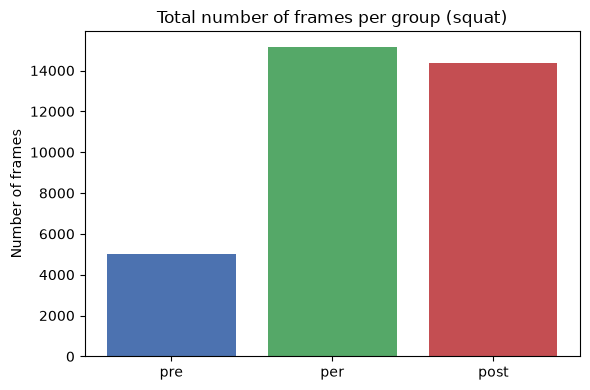

In [3]:
# ============================================================
# 2. CONFIGURATION
# ============================================================

# Directory containing the videos
directory = "."

# Groups to analyze
groups = ["pre", "per", "post"]

# Video file extensions
extensions = ["mp4"]

# Initialize result containers
results = []  # One row per video
total_frames_per_group = {}


# ============================================================
# 3. VIDEO FILE SEARCH AND FRAME COUNTING
# ============================================================

for group in groups:

    # Find all videos starting with squat_<group>
    files = []

    for ext in extensions:
        files += glob.glob(
            os.path.join(directory, f"squat_{group}*.{ext}")
        )

    files = sorted(set(files))

    # Initialize total frame count for the current group
    total_frames = 0

    # Process each video
    for file_path in files:

        cap = cv2.VideoCapture(file_path)

        if not cap.isOpened():
            print(f"Unable to open: {file_path}")
            continue

        # Retrieve video metadata
        n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        fps = cap.get(cv2.CAP_PROP_FPS)

        cap.release()

        # Update total frame count
        total_frames += n_frames

        # Store video information
        results.append({
            "group": group,
            "file": os.path.basename(file_path),
            "frames": n_frames,
            "fps": round(fps, 2),
            "duration_s": round(n_frames / fps, 2) if fps > 0 else np.nan,
        })

    # Store total frames for the current group
    total_frames_per_group[group] = total_frames

    print(
        f"Group '{group}': {len(files)} video(s), "
        f"{total_frames} frames in total"
    )


# ============================================================
# 4. RESULTS SUMMARY
# ============================================================

# Create a DataFrame containing video information
df = pd.DataFrame(results)

# Display detailed results for each video
print("\nVideo details:")
print(df.to_string(index=False))

# Display total number of frames per group
print("\nTotal frames per group:")

for group, n_frames in total_frames_per_group.items():
    print(f"  {group}: {n_frames}")

# Display overall frame count
print(
    f"\nOverall total: "
    f"{sum(total_frames_per_group.values())} frames"
)


# ============================================================
# 5. DATA VISUALIZATION
# ============================================================

plt.figure(figsize=(6, 4))

plt.bar(
    total_frames_per_group.keys(),
    total_frames_per_group.values(),
    color=["#4C72B0", "#55A868", "#C44E52"]
)

plt.ylabel("Number of frames")
plt.title("Total number of frames per group (squat)")

plt.tight_layout()
plt.show()


In [4]:

# ============================================================
# 6. CALCULATE 10% OF THE SMALLEST FRAME COUNT
# ============================================================

# Find the group with the smallest number of frames
min_frames = min(total_frames_per_group.values())

# Calculate 10% of the minimum frame count
ten_percent_frames = min_frames * 0.10

print(
    f"\n10% of the smallest frame count across groups: "
    f"{ten_percent_frames:.2f} frames"
)



10% of the smallest frame count across groups: 499.50 frames


In [6]:

# ============================================================
# 7. FRAME SAMPLING FUNCTION
# ============================================================

def calculate_indices(total_frames, target_frames):
    """
    Calculate evenly distributed frame indices across a video group.

    If the total number of frames is smaller than the target,
    all available frame indices are returned.
    """

    if total_frames <= target_frames:
        return list(range(total_frames))

    step = total_frames / target_frames

    return [int(i * step) for i in range(target_frames)]


# ============================================================
# 8. FRAME EXTRACTION CONFIGURATION
# ============================================================

# Target number of frames to extract per group
N_FRAMES_TARGET = 500


# ============================================================
# 9. FRAME EXTRACTION BY GROUP
# ============================================================

for group in groups:

    # Create output directory for the current group
    output_directory = f"dataset_squat_{group}"
    os.makedirs(output_directory, exist_ok=True)

    # Find all videos belonging to the current group
    files = []

    for ext in extensions:
        files += glob.glob(
            os.path.join(directory, f"squat_{group}*.{ext}")
        )

    files = sorted(set(files))

    # Calculate GLOBAL frame indices across all videos in the group
    global_indices = calculate_indices(
        total_frames_per_group[group],
        N_FRAMES_TARGET
    )

    offset = 0       # Number of frames in previously processed videos
    frame_count = 0  # Number of successfully extracted frames


    # ========================================================
    # 10. FRAME EXTRACTION FROM EACH VIDEO
    # ========================================================

    for file_path in files:

        cap = cv2.VideoCapture(file_path)

        if not cap.isOpened():
            print(f"Unable to open: {file_path}")
            continue

        n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        # Convert global indices into local video indices
        # Keep only indices belonging to the current video
        local_indices = {
            i - offset
            for i in global_indices
            if offset <= i < offset + n_frames
        }

        # Get video filename without extension
        base_name = os.path.splitext(
            os.path.basename(file_path)
        )[0]

        # Read frames sequentially (more reliable than cap.set
        # with many video codecs)
        position = 0

        while position < n_frames and local_indices:

            ret, frame = cap.read()

            if not ret:
                break

            # Save the frame if its index matches the sampling indices
            if position in local_indices:

                output_path = os.path.join(
                    output_directory,
                    f"{base_name}_frame_{position:06d}.jpg"
                )

                cv2.imwrite(output_path, frame)

                local_indices.discard(position)
                frame_count += 1

            position += 1

        # Release video resources
        cap.release()

        # Update global frame offset
        offset += n_frames


    # ========================================================
    # 11. EXTRACTION SUMMARY
    # ========================================================

    print(
        f"Group '{group}': {frame_count} frames extracted "
        f"into '{output_directory}'"
    )

Group 'pre': 500 frames extracted into 'dataset_squat_pre'
Group 'per': 500 frames extracted into 'dataset_squat_per'
Group 'post': 500 frames extracted into 'dataset_squat_post'


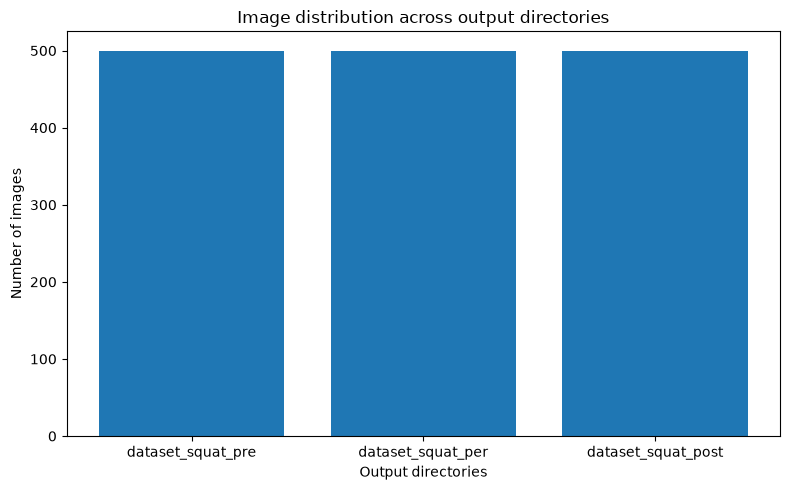

Number of images extracted per directory:
dataset_squat_pre: 500 images
dataset_squat_per: 500 images
dataset_squat_post: 500 images


In [7]:

# ============================================================
# 12. COUNT IMAGES IN EACH OUTPUT DIRECTORY
# ============================================================

# List of output directories
output_directories = [
    "dataset_squat_pre",
    "dataset_squat_per",
    "dataset_squat_post"
]

# Count the number of images in each directory
n_images = [
    len(os.listdir(directory))
    for directory in output_directories
]


# ============================================================
# 13. IMAGE DISTRIBUTION VISUALIZATION
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(output_directories, n_images)

plt.xlabel("Output directories")
plt.ylabel("Number of images")
plt.title("Image distribution across output directories")

plt.tight_layout()
plt.show()


# ============================================================
# 14. IMAGE EXTRACTION SUMMARY
# ============================================================

print("Number of images extracted per directory:")

for directory, n in zip(output_directories, n_images):
    print(f"{directory}: {n} images")
